# SPREAD LOCATOR
## A Statistical Distribution Analysis Model

**Project:** Spread Locator

**Domain:** Mathematics & Advanced Statistics

**Objective:** To analyze customer transaction behavior
using statistical distributions and probability analysis.

**Dataset:** E-commerce Transaction Dataset

**Tools:** Python, NumPy, Pandas, SciPy, Statsmodels,
Matplotlib and Seaborn.

In [2]:
# Import Required Libraries

import numpy as np
import pandas as pd

import scipy.stats as stats
import statsmodels.api as sm

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

print("All Libraries Imported Successfully!")

All Libraries Imported Successfully!


In [5]:
# Load Dataset

df = pd.read_excel("spread_locator_dataset.xlsx")

print("Dataset Loaded Successfully!")
df.head()

Dataset Loaded Successfully!


,transaction_id,customer_id,transaction_amount,transaction_date,transaction_count,region,transaction_status
0,e98aa092-3770-4fdb-9502-5b5a6a244811,CUST2824,3821.34,2023-01-26,3,North,Fail
1,11ba6918-dba0-41e5-96cf-f5a7b95f0103,CUST1409,2781.84,2023-01-28,0,East,Fail
2,82b7654b-6eb7-4579-89a0-1a9edec0a7bb,CUST5506,4120.97,2023-01-28,0,South,Fail
3,f7166574-f400-4d53-b526-0b11f6619ddf,CUST5012,6383.78,2023-01-18,2,South,Success
4,8632fe26-b507-4068-9c68-1b2fa04fecb3,CUST4657,2651.61,2023-01-04,4,North,Success


In [8]:
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])
df.info()

Total Rows: 220
Total Columns: 7
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 220 entries, 0 to 219
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   transaction_id      220 non-null    object        
 1   customer_id         220 non-null    object        
 2   transaction_amount  220 non-null    float64       
 3   transaction_date    220 non-null    datetime64[ns]
 4   transaction_count   220 non-null    int64         
 5   region              220 non-null    object        
 6   transaction_status  220 non-null    object        
dtypes: datetime64[ns](1), float64(1), int64(1), object(4)
memory usage: 12.2+ KB


In [9]:
print("Missing Values in Each Column:")
print(df.isnull().sum())

Missing Values in Each Column:
transaction_id        0
customer_id           0
transaction_amount    0
transaction_date      0
transaction_count     0
region                0
transaction_status    0
dtype: int64


In [10]:
df.describe()

,transaction_amount,transaction_date,transaction_count
count,220.000000,220,220.000000
mean,3365.192409,2023-01-15 17:14:10.909090816,2.854545
min,804.420000,2023-01-01 00:00:00,0.000000
25%,2124.205000,2023-01-07 00:00:00,1.750000
50%,3077.715000,2023-01-16 00:00:00,3.000000
75%,3950.737500,2023-01-23 06:00:00,4.000000
max,20462.840000,2023-01-31 00:00:00,9.000000
std,1985.705409,NaN,1.797189


In [11]:
print(df['transaction_status'].value_counts())

transaction_status
Fail       122
Success     98
Name: count, dtype: int64


In [12]:
# Mean, Median and Mode

mean_value = df['transaction_amount'].mean()

median_value = df['transaction_amount'].median()

mode_value = df['transaction_amount'].mode()[0]

print("Mean:", round(mean_value, 2))
print("Median:", round(median_value, 2))
print("Mode:", round(mode_value, 2))

Mean: 3365.19
Median: 3077.72
Mode: 804.42


In [13]:
# Variance and Standard Deviation

variance = df['transaction_amount'].var()

std_dev = df['transaction_amount'].std()

print("Variance:", round(variance, 2))
print("Standard Deviation:", round(std_dev, 2))

Variance: 3943025.97
Standard Deviation: 1985.71


In [14]:
# Skewness Analysis

skewness = df['transaction_amount'].skew()

print("Skewness:", round(skewness, 4))

if skewness > 0:
    print("Distribution is Positively Skewed")

elif skewness < 0:
    print("Distribution is Negatively Skewed")

else:
    print("Distribution is Symmetrical")

Skewness: 3.7558
Distribution is Positively Skewed


In [15]:
# Kurtosis Analysis

kurtosis = df['transaction_amount'].kurt()

print("Kurtosis:", round(kurtosis, 4))

if kurtosis > 0:
    print("Leptokurtic Distribution")

elif kurtosis < 0:
    print("Platykurtic Distribution")

else:
    print("Mesokurtic Distribution")

Kurtosis: 25.9462
Leptokurtic Distribution


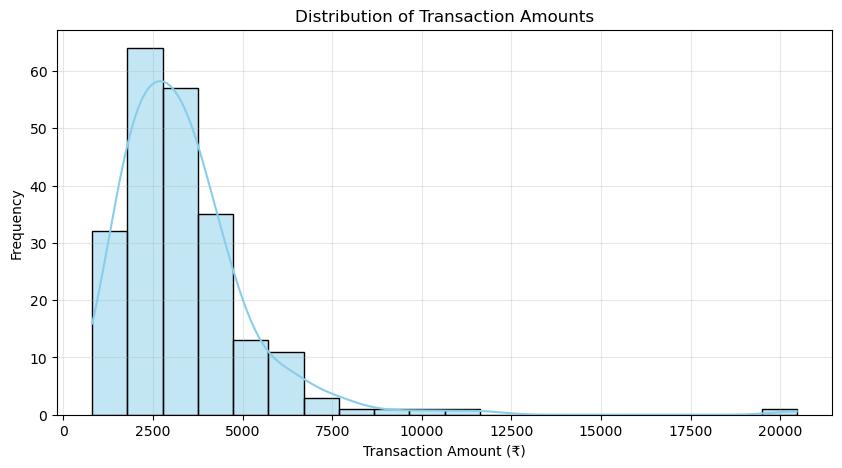

In [16]:
# Histogram of Transaction Amounts

plt.figure(figsize=(10, 5))

sns.histplot(
    df['transaction_amount'],
    bins=20,
    kde=True,
    color='skyblue'
)

plt.title('Distribution of Transaction Amounts')
plt.xlabel('Transaction Amount (₹)')
plt.ylabel('Frequency')

plt.grid(alpha=0.3)
plt.show()

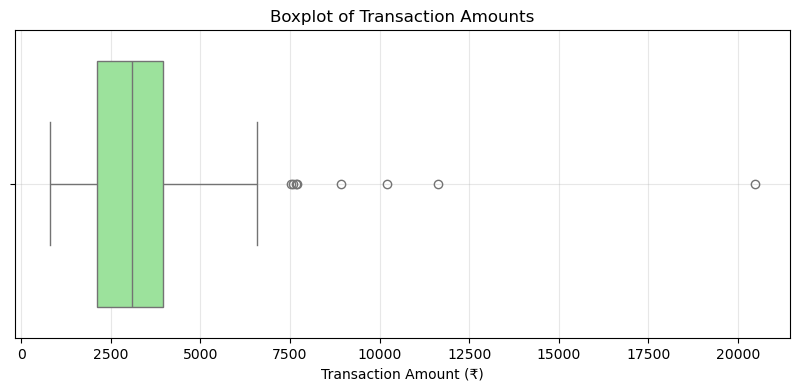

In [17]:
# Boxplot of Transaction Amounts

plt.figure(figsize=(10, 4))

sns.boxplot(
    x=df['transaction_amount'],
    color='lightgreen'
)

plt.title('Boxplot of Transaction Amounts')
plt.xlabel('Transaction Amount (₹)')

plt.grid(alpha=0.3)
plt.show()

## Descriptive Statistical Analysis

In this step, descriptive statistical measures
were calculated for customer transaction amounts.

The analysis includes Mean, Median, Mode,
Variance, Standard Deviation, Skewness and Kurtosis.

Histogram was used to understand the distribution
pattern, while Boxplot was used to identify
potential outliers.

These statistical measures help us understand
the spread and behavior of transaction amounts.


# PART A – THEORETICAL FOUNDATION

## Q1. What is Statistical Distribution?

A statistical distribution describes how values of a variable are spread or distributed across different possible outcomes.

It helps us understand the frequency, probability, central tendency and variation of data.

### Example:
In our Spread Locator project, transaction amounts represent customer purchasing behavior.

Statistical distributions help us understand:
- How frequently different transaction amounts occur.
- Whether transactions are normally distributed.
- Whether transaction amounts are positively or negatively skewed.
- How likely unusually large transactions are.

### Types of Statistical Distributions:
1. Discrete Distribution
2. Continuous Distribution



## Q2. What is a Q-Q Plot and why is it used?

A Q-Q (Quantile-Quantile) Plot is a graphical tool used to compare the distribution of a dataset with a theoretical distribution.

### Why is it used?
- To check whether data follows a normal distribution.
- To identify deviations from normality.
- To detect possible outliers.
- To compare two probability distributions.

### Interpretation:
- Points close to the straight line indicate a good fit.
- Points far from the line indicate deviations.
- Curved patterns may indicate skewness or other distribution differences.

### Application in our project:
We will use a Q-Q Plot to check whether transaction amounts follow a normal distribution.



## Q3. Difference between Discrete and Continuous Distributions

| Discrete Distribution | Continuous Distribution |
|---|---|
| Takes countable values | Takes values over a continuous range |
| Represents counts | Represents measurements |
| Uses PMF | Uses PDF |
| Example: Number of transactions | Example: Transaction amount |
| Bernoulli, Binomial, Poisson | Normal, Log-Normal, Exponential |



## Q4. What is Bernoulli Distribution?

Bernoulli Distribution is a discrete probability distribution
that represents an experiment with only two possible outcomes:

1. Success (1)
2. Failure (0)

It is used when an experiment has exactly two possible outcomes.

### Probability Formula:

P(X = x) = p^x (1-p)^(1-x)

Where:
- p = Probability of success
- 1-p = Probability of failure
- x = 0 or 1

### Example:

In an e-commerce platform, a transaction can be either:

- Success = 1
- Failure = 0

If the probability of success is 0.7,
then the probability of failure is 0.3.

### Application in our project:

We can use Bernoulli Distribution to analyze
the success and failure status of customer transactions.



## Q5. What is Binomial Distribution?

Binomial Distribution is a discrete probability distribution
that calculates the number of successes in a fixed number
of independent trials.

Each trial has only two possible outcomes:
Success or Failure.

### Probability Formula:

P(X = x) = C(n,x) × p^x × (1-p)^(n-x)

Where:
- n = Total number of trials
- x = Number of successes
- p = Probability of success
- 1-p = Probability of failure
- C(n,x) = Combination of n items taken x at a time

### Example:

Suppose an e-commerce platform processes 10 transactions.

If the probability of success is 0.7,
the Binomial Distribution can calculate
the probability of exactly 7 successful transactions.

### Application in our project:

We can use Binomial Distribution to model
the number of successful transactions
among a fixed number of independent transactions.



## Q6. Explain Log-Normal Distribution

Log-Normal Distribution is a continuous probability
distribution in which the logarithm of a random variable
follows a normal distribution.

It is generally used for positive values and often
produces a right-skewed distribution.

### Characteristics:

1. Values are always positive.
2. The distribution is right-skewed.
3. It has a long right tail.
4. It is useful for modeling financial and transaction data.

### Example:

In an e-commerce platform, most customers may make
small or medium purchases, while a few customers
may make very large purchases.

This type of behavior can sometimes be modeled
using Log-Normal Distribution.

### Application in our project:

We will fit a Log-Normal Distribution to transaction
amounts and compare it with other distributions
to understand customer purchasing behavior.



## Q7. Explain Power Law Distribution

Power Law Distribution is a probability distribution
in which the probability of an event decreases
as a power of its size or magnitude increases.

It is commonly used to describe data where
a small number of events have very large values,
while most events have relatively small values.

### Mathematical Formula:

P(X = x) ∝ x^(-α)

Where:
- x = Value of the variable
- α = Power law exponent
- P(X = x) = Probability of observing a value x

### Characteristics:

1. It has a heavy tail.
2. Most values are relatively small.
3. A few values can be extremely large.
4. It is useful for studying highly uneven distributions.

### Example:

In an e-commerce platform, most customers may
make small purchases, while a few customers
make very large purchases.

### Application in our project:

We will analyze transaction amounts using
Power Law Distribution and compare its behavior
with Log-Normal Distribution.



## Q8. What is Box-Cox Transform?

Box-Cox Transformation is a statistical technique
used to transform positive numerical data
to make it more normally distributed.

It helps reduce skewness and stabilize variance.

### Mathematical Formula:

For λ ≠ 0:

Y(λ) = (Y^λ - 1) / λ

For λ = 0:

Y(λ) = ln(Y)

Where:
- Y = Original positive data
- λ = Transformation parameter
- Y(λ) = Transformed data

### Characteristics:

1. Reduces skewness.
2. Helps stabilize variance.
3. Can make data closer to a normal distribution.
4. Requires strictly positive input values.

### Example:

Transaction amounts in an e-commerce dataset
may be highly right-skewed.

Box-Cox Transformation can help reduce
this skewness.

### Application in our project:

We will apply Box-Cox Transformation to
transaction amounts and compare the distribution
before and after transformation.



## Q9. Explain Poisson Distribution with an Example

Poisson Distribution is a discrete probability
distribution used to calculate the probability
of a given number of events occurring
within a fixed interval of time or space.

It is useful when events occur independently
at a constant average rate.

### Mathematical Formula:

P(X = x) = (e^(-λ) × λ^x) / x!

Where:
- λ = Average number of events
- x = Number of events
- e = Euler's number (approximately 2.718)
- x! = Factorial of x

### Characteristics:

1. It is a discrete probability distribution.
2. It is used for counting events.
3. Events occur independently.
4. The average rate is represented by λ.
5. Mean and variance are both equal to λ.

### Example:

An e-commerce platform receives an average
of 5 transactions per hour.

Poisson Distribution can calculate the probability
of receiving exactly 3 transactions in an hour.

### Application in our project:

We will use Poisson Distribution to model
the number of transactions occurring per day.



## Q10. What is Z-score Probability?

A Z-score is a statistical measurement that describes
how many standard deviations a data point is away
from the mean of a dataset.

It helps us understand the relative position of a value
within a distribution.

### Mathematical Formula:

Z = (X - μ) / σ

Where:
- X = Individual data value
- μ = Mean of the dataset
- σ = Standard deviation
- Z = Standardized score

### Characteristics:

1. Z-score can be positive, negative or zero.
2. A positive Z-score indicates a value above the mean.
3. A negative Z-score indicates a value below the mean.
4. A Z-score of zero indicates a value equal to the mean.

### Example:

Suppose the average transaction amount is ₹3,000
and the standard deviation is ₹1,000.

For a transaction amount of ₹5,000:

Z = (5000 - 3000) / 1000

Z = 2

This means the transaction amount is
2 standard deviations above the mean.

### Application in our project:

We will calculate Z-scores for transaction amounts
and estimate the probability of transactions
exceeding ₹5,000 using statistical methods.



## Q11. Differentiate Probability Density Function (PDF) and Cumulative Distribution Function (CDF)

### Probability Density Function (PDF):

PDF describes the relative likelihood of different
values of a continuous random variable.

The area under the PDF curve represents probability.

### Cumulative Distribution Function (CDF):

CDF describes the probability that a random variable
will be less than or equal to a particular value.

### Mathematical Formula:

PDF: f(x)

CDF: F(x) = P(X ≤ x)

### Difference between PDF and CDF:

| PDF | CDF |
|---|---|
| Probability Density Function | Cumulative Distribution Function |
| Shows probability density | Shows cumulative probability |
| Represents density at a given value | Represents probability up to a value |
| Total area under curve is 1 | Values range from 0 to 1 |
| Used to study distribution shape | Used to calculate cumulative probability |

### Example:

In our e-commerce dataset:

PDF helps us understand the density
of different transaction amounts.

CDF helps us calculate the probability
that a transaction amount is less than
or equal to ₹5,000.

### Application in our project:

We will generate PDF and CDF plots
for transaction amounts and interpret
the probability distribution.


# PART B – DATA ANALYSIS & TESTING

## Task 1: Bernoulli Distribution

### Objective
To analyze transaction success and failure
probabilities using Bernoulli Distribution.

In [23]:
# Bernoulli Distribution

# Convert transaction status into binary values

df['transaction_binary'] = (
    df['transaction_status'] == 'Success'
).astype(int)

# Calculate probabilities

total_transactions = len(df)

success_count = df['transaction_binary'].sum()

failure_count = total_transactions - success_count

p = success_count / total_transactions

q = 1 - p

print("Total Transactions:", total_transactions)
print("Successful Transactions:", success_count)
print("Failed Transactions:", failure_count)

print("Probability of Success:", round(p, 4))
print("Probability of Failure:", round(q, 4))

Total Transactions: 220
Successful Transactions: 98
Failed Transactions: 122
Probability of Success: 0.4455
Probability of Failure: 0.5545


Bernoulli PMF:
Failure (0): 0.5545
Success (1): 0.4455


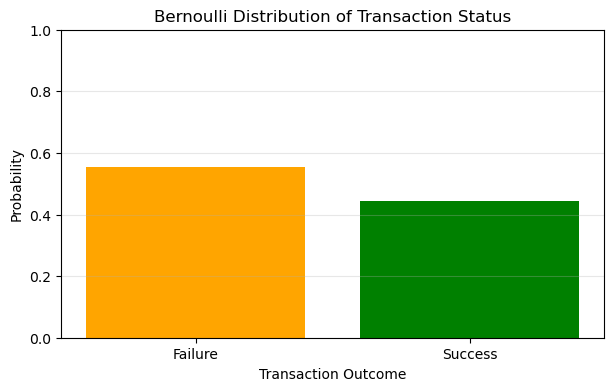

In [24]:
# Bernoulli Probability Mass Function (PMF)

x = np.array([0, 1])

bernoulli_probabilities = stats.bernoulli.pmf(x, p)

print("Bernoulli PMF:")
print("Failure (0):", round(bernoulli_probabilities[0], 4))
print("Success (1):", round(bernoulli_probabilities[1], 4))

# Visualization

plt.figure(figsize=(7, 4))

plt.bar(
    ['Failure', 'Success'],
    bernoulli_probabilities,
    color=['orange', 'green']
)

plt.title('Bernoulli Distribution of Transaction Status')
plt.xlabel('Transaction Outcome')
plt.ylabel('Probability')

plt.ylim(0, 1)
plt.grid(axis='y', alpha=0.3)
plt.show()

### Bernoulli Distribution – Interpretation

The transaction status was converted into binary values,
where Success = 1 and Failure = 0.

Out of 220 transactions, 98 were successful
and 122 were failed.

The probability of success was approximately 0.4455
and the probability of failure was approximately 0.5545.

The results show that the observed transaction
success rate was approximately 44.55%.

## Binomial Distribution

### Objective
To model weekly transaction counts using
Binomial Distribution and analyze their probabilities.

In [26]:
# Weekly Transaction Count

weekly_count = df['transaction_count']

print("Total Records:", len(weekly_count))
print("Mean Weekly Count:", round(weekly_count.mean(), 2))
print("Minimum Count:", weekly_count.min())
print("Maximum Count:", weekly_count.max())

print("\nWeekly Transaction Frequency:")
print(weekly_count.value_counts().sort_index())

Total Records: 220
Mean Weekly Count: 2.85
Minimum Count: 0
Maximum Count: 9

Weekly Transaction Frequency:
transaction_count
0    15
1    40
2    48
3    47
4    27
5    25
6    12
7     3
8     2
9     1
Name: count, dtype: int64


In [27]:
# Binomial Distribution

n = 9

p_binomial = weekly_count.mean() / n

# Ensure probability is between 0 and 1

print("Number of Trials (n):", n)
print("Estimated Probability (p):", round(p_binomial, 4))

# Calculate Binomial PMF

x_binomial = np.arange(0, n + 1)

binomial_probabilities = stats.binom.pmf(
    x_binomial,
    n,
    p_binomial
)

print("\nBinomial Probabilities:")

for x, probability in zip(
    x_binomial,
    binomial_probabilities
):
    print(f"Count {x}: {probability:.4f}")

Number of Trials (n): 9
Estimated Probability (p): 0.3172

Binomial Probabilities:
Count 0: 0.0323
Count 1: 0.1349
Count 2: 0.2507
Count 3: 0.2717
Count 4: 0.1893
Count 5: 0.0879
Count 6: 0.0272
Count 7: 0.0054
Count 8: 0.0006
Count 9: 0.0000


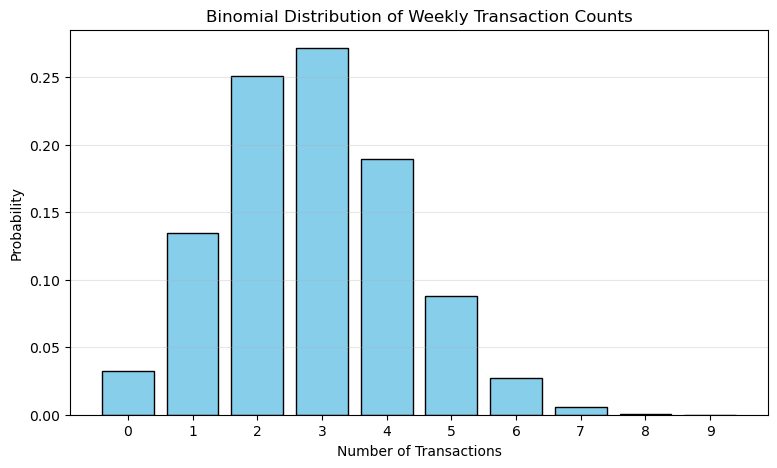

In [28]:
# Binomial Distribution Visualization

plt.figure(figsize=(9, 5))

plt.bar(
    x_binomial,
    binomial_probabilities,
    color='skyblue',
    edgecolor='black'
)

plt.title('Binomial Distribution of Weekly Transaction Counts')
plt.xlabel('Number of Transactions')
plt.ylabel('Probability')

plt.xticks(x_binomial)
plt.grid(axis='y', alpha=0.3)

plt.show()

### Binomial Distribution – Interpretation

The weekly transaction count was analyzed
using Binomial Distribution.

For exploratory modeling, the number of trials
was assumed to be 9 based on the maximum
observed transaction count.

The success probability was estimated using
the observed mean weekly transaction count.

The Binomial PMF was generated to understand
the probability of different weekly transaction counts.

This model is provisional because the actual
number of possible trials per week needs
business-level confirmation.

## Poisson Distribution

### Objective

To model the number of transactions occurring
per day using Poisson Distribution.

Poisson Distribution helps us calculate
the probability of a specific number of
transactions occurring within a fixed time interval.

In [29]:
# Daily Transaction Count Analysis

df['transaction_date'] = pd.to_datetime(
    df['transaction_date']
)

daily_transactions = (
    df.groupby('transaction_date')
    .size()
)

# Include dates with zero transactions

date_range = pd.date_range(
    start=df['transaction_date'].min(),
    end=df['transaction_date'].max(),
    freq='D'
)

daily_transactions = (
    daily_transactions
    .reindex(date_range, fill_value=0)
)

print("Total Days:", len(daily_transactions))

print("\nDaily Transaction Counts:")
print(daily_transactions.head(10))

Total Days: 31

Daily Transaction Counts:
2023-01-01     6
2023-01-02    12
2023-01-03    10
2023-01-04     7
2023-01-05     9
2023-01-06     6
2023-01-07     7
2023-01-08     5
2023-01-09    10
2023-01-10     8
Freq: D, dtype: int64


In [30]:
# Calculate Lambda

lambda_value = daily_transactions.mean()

print("Average Daily Transactions (Lambda):",
      round(lambda_value, 4))

print("Maximum Daily Transactions:",
      daily_transactions.max())

print("Minimum Daily Transactions:",
      daily_transactions.min())

Average Daily Transactions (Lambda): 7.0968
Maximum Daily Transactions: 12
Minimum Daily Transactions: 3


In [31]:
# Poisson Probability Mass Function

x_poisson = np.arange(
    0,
    daily_transactions.max() + 1
)

poisson_probabilities = stats.poisson.pmf(
    x_poisson,
    lambda_value
)

print("Poisson Distribution Probabilities:\n")

for x, probability in zip(
    x_poisson,
    poisson_probabilities
):
    print(f"{x} Transactions: {probability:.4f}")

Poisson Distribution Probabilities:

0 Transactions: 0.0008
1 Transactions: 0.0059
2 Transactions: 0.0208
3 Transactions: 0.0493
4 Transactions: 0.0875
5 Transactions: 0.1242
6 Transactions: 0.1469
7 Transactions: 0.1489
8 Transactions: 0.1321
9 Transactions: 0.1042
10 Transactions: 0.0739
11 Transactions: 0.0477
12 Transactions: 0.0282


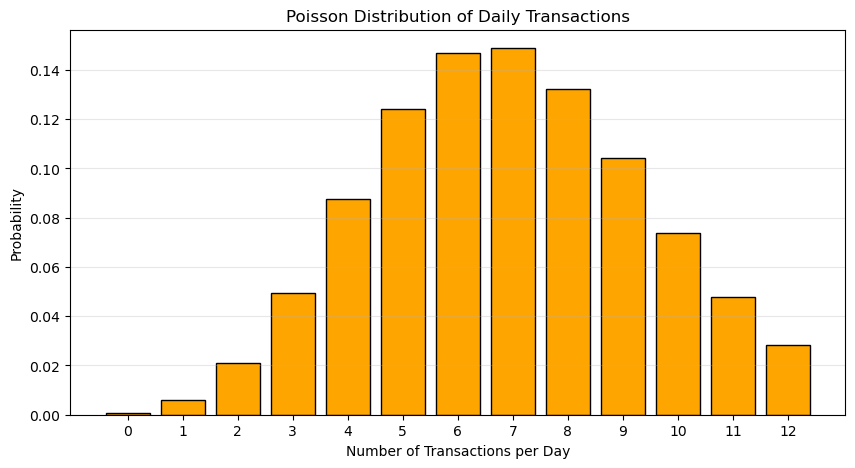

In [32]:
# Poisson Distribution Graph

plt.figure(figsize=(10, 5))

plt.bar(
    x_poisson,
    poisson_probabilities,
    color='orange',
    edgecolor='black'
)

plt.title('Poisson Distribution of Daily Transactions')
plt.xlabel('Number of Transactions per Day')
plt.ylabel('Probability')

plt.xticks(x_poisson)
plt.grid(axis='y', alpha=0.3)

plt.show()

In [33]:
# Compare Actual and Expected Frequencies

actual_frequency = (
    daily_transactions
    .value_counts()
    .reindex(x_poisson, fill_value=0)
)

expected_frequency = (
    poisson_probabilities * len(daily_transactions)
)

comparison = pd.DataFrame({
    'Transactions_Per_Day': x_poisson,
    'Actual_Frequency': actual_frequency.values,
    'Expected_Frequency': expected_frequency
})

display(comparison.round(2))

,Transactions_Per_Day,Actual_Frequency,Expected_Frequency
0,0,0,0.03
1,1,0,0.18
2,2,0,0.65
3,3,1,1.53
4,4,1,2.71
5,5,6,3.85
6,6,8,4.55
7,7,4,4.62
8,8,3,4.09
9,9,1,3.23


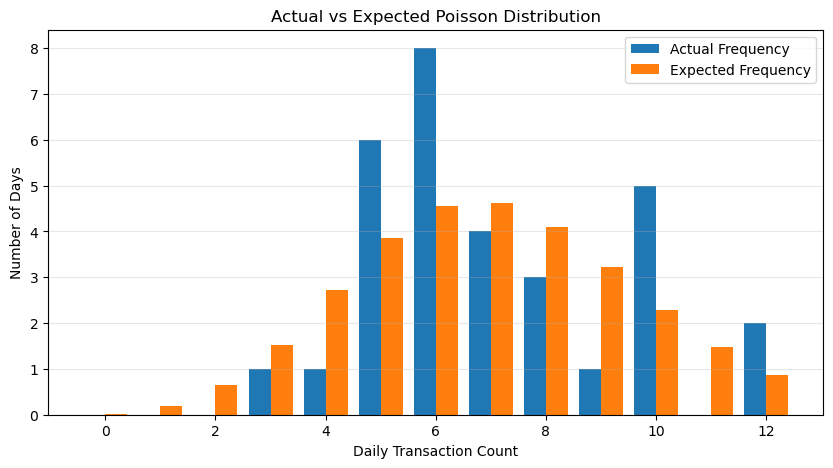

In [34]:
# Actual vs Expected Frequency

plt.figure(figsize=(10, 5))

plt.bar(
    x_poisson - 0.2,
    actual_frequency.values,
    width=0.4,
    label='Actual Frequency'
)

plt.bar(
    x_poisson + 0.2,
    expected_frequency,
    width=0.4,
    label='Expected Frequency'
)

plt.title('Actual vs Expected Poisson Distribution')
plt.xlabel('Daily Transaction Count')
plt.ylabel('Number of Days')

plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.show()

### Poisson Distribution – Interpretation

In this analysis, daily transaction counts
were calculated from the transaction dataset.

The average daily transaction count was
used as the Lambda (λ) parameter.

Poisson PMF was calculated to estimate
the probability of different daily transaction counts.

Actual transaction frequencies were compared
with expected Poisson frequencies.

This comparison helps evaluate how well
the Poisson Distribution represents daily
transaction activity.

## Log-Normal and Power Law Distribution

### Objective

To model customer transaction amounts using
Log-Normal and Power Law Distributions.

The purpose is to understand the distribution
pattern of transaction amounts and compare
both statistical models.

In [37]:
# Prepare Transaction Amount Data

amounts = df['transaction_amount'].dropna()

# Check positive values

amounts = amounts[amounts > 0]

print("Total Transaction Amounts:", len(amounts))
print("Minimum Amount:", amounts.min())
print("Maximum Amount:", amounts.max())
print("Mean Amount:", round(amounts.mean(), 2))

Total Transaction Amounts: 220
Minimum Amount: 804.42
Maximum Amount: 20462.84
Mean Amount: 3365.19


In [38]:
# Fit Log-Normal Distribution

lognorm_shape, lognorm_loc, lognorm_scale = stats.lognorm.fit(
    amounts,
    floc=0
)

print("Log-Normal Distribution Parameters")

print("Shape:", round(lognorm_shape, 4))
print("Location:", round(lognorm_loc, 4))
print("Scale:", round(lognorm_scale, 4))

Log-Normal Distribution Parameters
Shape: 0.4749
Location: 0
Scale: 2983.1591


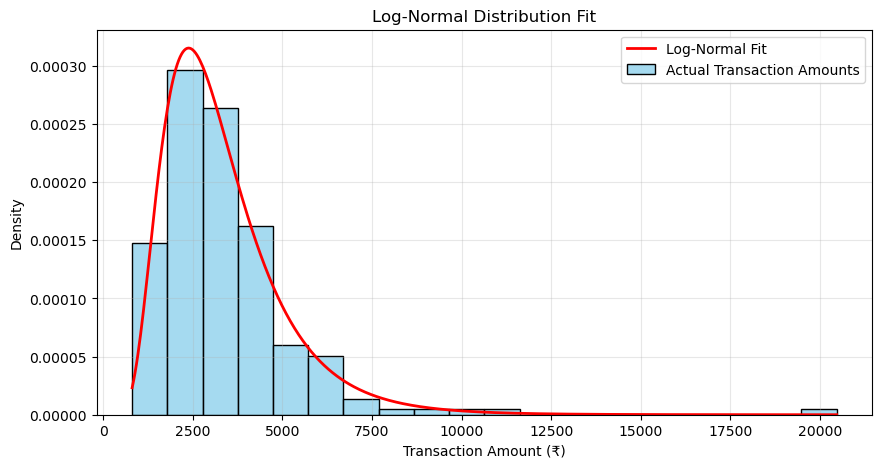

In [39]:
# Log-Normal Distribution Visualization

x = np.linspace(amounts.min(), amounts.max(), 500)

lognorm_pdf = stats.lognorm.pdf(
    x,
    lognorm_shape,
    loc=lognorm_loc,
    scale=lognorm_scale
)

plt.figure(figsize=(10, 5))

sns.histplot(
    amounts,
    bins=20,
    stat='density',
    color='skyblue',
    label='Actual Transaction Amounts'
)

plt.plot(
    x,
    lognorm_pdf,
    color='red',
    linewidth=2,
    label='Log-Normal Fit'
)

plt.title('Log-Normal Distribution Fit')
plt.xlabel('Transaction Amount (₹)')
plt.ylabel('Density')

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [40]:
# Fit Power Law (Pareto Type-I) Distribution

power_shape, power_loc, power_scale = stats.pareto.fit(
    amounts,
    floc=0
)

print("Power Law Distribution Parameters")

print("Shape (Alpha):", round(power_shape, 4))
print("Location:", round(power_loc, 4))
print("Scale:", round(power_scale, 4))

Power Law Distribution Parameters
Shape (Alpha): 0.763
Location: 0
Scale: 804.42


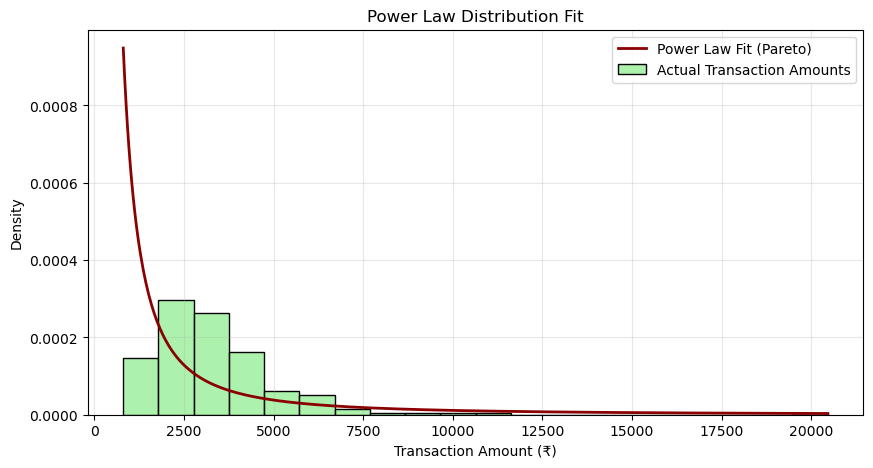

In [41]:
# Power Law Distribution Visualization

power_pdf = stats.pareto.pdf(
    x,
    power_shape,
    loc=power_loc,
    scale=power_scale
)

plt.figure(figsize=(10, 5))

sns.histplot(
    amounts,
    bins=20,
    stat='density',
    color='lightgreen',
    label='Actual Transaction Amounts'
)

plt.plot(
    x,
    power_pdf,
    color='darkred',
    linewidth=2,
    label='Power Law Fit (Pareto)'
)

plt.title('Power Law Distribution Fit')
plt.xlabel('Transaction Amount (₹)')
plt.ylabel('Density')

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [42]:
# Calculate Log-Likelihood

lognorm_loglik = np.sum(
    stats.lognorm.logpdf(
        amounts,
        lognorm_shape,
        loc=lognorm_loc,
        scale=lognorm_scale
    )
)

power_loglik = np.sum(
    stats.pareto.logpdf(
        amounts,
        power_shape,
        loc=power_loc,
        scale=power_scale
    )
)

# Calculate AIC

n = len(amounts)

lognorm_aic = 2 * 2 - 2 * lognorm_loglik

power_aic = 2 * 2 - 2 * power_loglik

# Comparison Table

comparison = pd.DataFrame({
    'Distribution': ['Log-Normal', 'Power Law (Pareto)'],
    'Log_Likelihood': [lognorm_loglik, power_loglik],
    'AIC': [lognorm_aic, power_aic]
})

display(comparison.round(4))

,Distribution,Log_Likelihood,AIC
0,Log-Normal,-1908.5139,3821.0278
1,Power Law (Pareto),-2039.6719,4083.3438


In [43]:
# Compare AIC Values

if lognorm_aic < power_aic:
    print("Log-Normal Distribution has lower AIC.")
    print("It is preferred among these two fitted models.")

elif power_aic < lognorm_aic:
    print("Power Law Distribution has lower AIC.")
    print("It is preferred among these two fitted models.")

else:
    print("Both models have equal AIC.")

Log-Normal Distribution has lower AIC.
It is preferred among these two fitted models.


### Log-Normal and Power Law – Interpretation

In this analysis, transaction amounts were fitted
using Log-Normal and Pareto-based Power Law models.

Both distributions were visualized and their
Log-Likelihood and AIC values were calculated.

The AIC comparison was used to identify
the relatively preferred model among the two.

The final distribution selection should also consider
the visual fit and goodness-of-fit testing.

This analysis helps understand the behavior
of customer transaction amounts.

    ##  Q-Q Plot and Normality Testing

### Objective

To examine whether transaction amounts follow
a normal distribution using Q-Q Plot and
Shapiro-Wilk statistical testing.

The analysis helps identify deviations
from normality in transaction data.

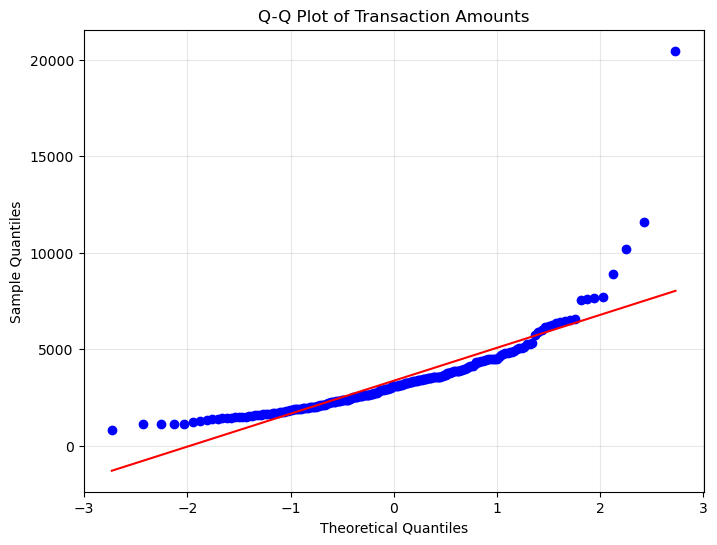

In [45]:
# Q-Q Plot for Transaction Amounts

plt.figure(figsize=(8, 6))

stats.probplot(
    df['transaction_amount'],
    dist='norm',
    plot=plt
)

plt.title('Q-Q Plot of Transaction Amounts')
plt.xlabel('Theoretical Quantiles')
plt.ylabel('Sample Quantiles')

plt.grid(alpha=0.3)
plt.show()

In [46]:
# Shapiro-Wilk Normality Test

shapiro_stat, shapiro_p = stats.shapiro(
    df['transaction_amount']
)

print("Shapiro-Wilk Test Results")

print("Test Statistic:", round(shapiro_stat, 4))
print("P-value:", shapiro_p)

alpha = 0.05

if shapiro_p < alpha:
    print("\nConclusion: Reject the Null Hypothesis.")
    print("Data does not follow a normal distribution.")

else:
    print("\nConclusion: Fail to Reject the Null Hypothesis.")
    print("There is insufficient evidence against normality.")

Shapiro-Wilk Test Results
Test Statistic: 0.7361
P-value: 1.9104194773842572e-18

Conclusion: Reject the Null Hypothesis.
Data does not follow a normal distribution.


In [47]:
# Log Transformation

log_amounts = np.log(
    df['transaction_amount']
)

# Shapiro-Wilk Test on Log Transformed Data

log_stat, log_p = stats.shapiro(log_amounts)

print("Original Data Shapiro P-value:",
      shapiro_p)

print("Log Transformed Shapiro P-value:",
      log_p)

Original Data Shapiro P-value: 1.9104194773842572e-18
Log Transformed Shapiro P-value: 0.10614734012895588


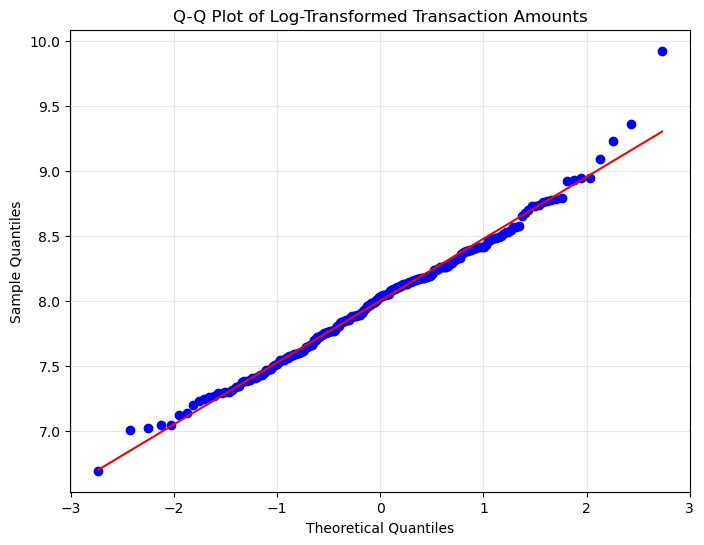

In [48]:
# Q-Q Plot after Log Transformation

plt.figure(figsize=(8, 6))

stats.probplot(
    log_amounts,
    dist='norm',
    plot=plt
)

plt.title('Q-Q Plot of Log-Transformed Transaction Amounts')
plt.xlabel('Theoretical Quantiles')
plt.ylabel('Sample Quantiles')

plt.grid(alpha=0.3)
plt.show()

### Q-Q Plot and Normality Testing – Interpretation

In this analysis, the normality of transaction
amounts was examined using a Q-Q Plot
and the Shapiro-Wilk test.

The Shapiro-Wilk test was used to evaluate
the null hypothesis of normality at a
significance level of 0.05.

A logarithmic transformation was also applied
to examine whether the distribution becomes
closer to normal.

The original and transformed Q-Q plots were
compared to understand the effect of transformation.

## Box-Cox Transformation

### Objective

To apply Box-Cox Transformation on transaction
amounts to reduce skewness and stabilize variance.

The original and transformed data will be compared
using statistical measures and visualizations.

In [50]:
# Box-Cox Transformation

amounts = df['transaction_amount'].dropna()

# Box-Cox requires strictly positive values

boxcox_data, lambda_value = stats.boxcox(amounts)

print("Optimal Lambda:", round(lambda_value, 4))

print("\nOriginal Data:")
print("Mean:", round(amounts.mean(), 2))
print("Skewness:", round(amounts.skew(), 4))

print("\nTransformed Data:")
print("Mean:", round(boxcox_data.mean(), 4))
print("Skewness:", round(pd.Series(boxcox_data).skew(), 4))

Optimal Lambda: -0.1808

Original Data:
Mean: 3365.19
Skewness: 3.7558

Transformed Data:
Mean: 4.2239
Skewness: -0.0107


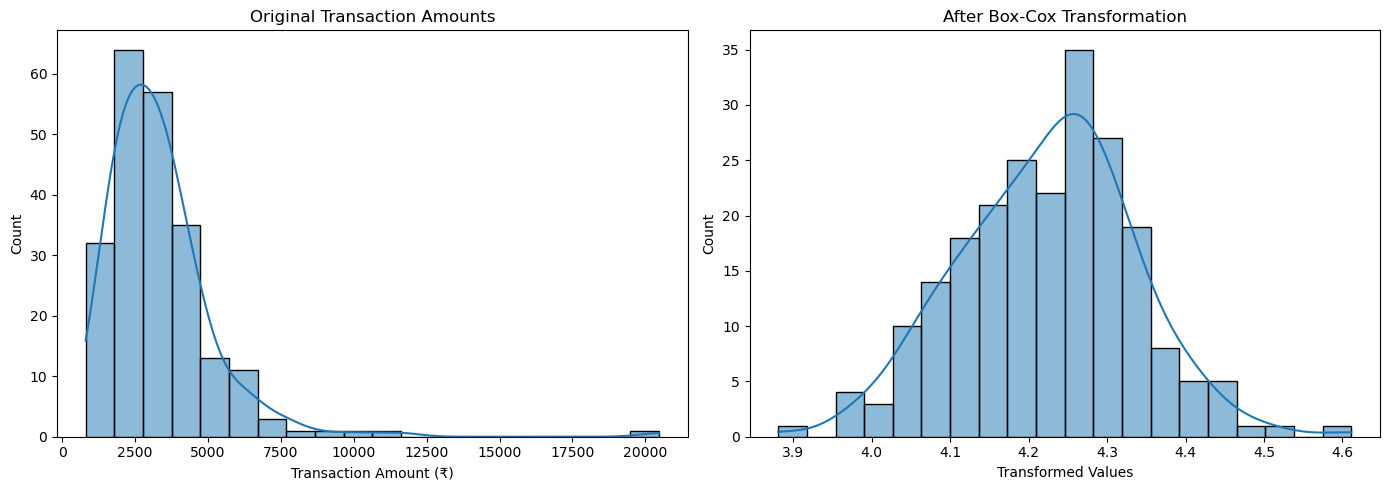

In [51]:
# Before and After Box-Cox Transformation

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Original Data

sns.histplot(
    amounts,
    bins=20,
    kde=True,
    ax=axes[0]
)

axes[0].set_title('Original Transaction Amounts')
axes[0].set_xlabel('Transaction Amount (₹)')

# Transformed Data

sns.histplot(
    boxcox_data,
    bins=20,
    kde=True,
    ax=axes[1]
)

axes[1].set_title('After Box-Cox Transformation')
axes[1].set_xlabel('Transformed Values')

plt.tight_layout()
plt.show()

In [52]:
# Statistical Comparison

comparison_boxcox = pd.DataFrame({
    'Measure': ['Mean', 'Standard Deviation',
                'Skewness', 'Kurtosis'],

    'Original Data': [
        amounts.mean(),
        amounts.std(),
        amounts.skew(),
        amounts.kurt()
    ],

    'Box-Cox Transformed': [
        pd.Series(boxcox_data).mean(),
        pd.Series(boxcox_data).std(),
        pd.Series(boxcox_data).skew(),
        pd.Series(boxcox_data).kurt()
    ]
})

display(comparison_boxcox.round(4))

,Measure,Original Data,Box-Cox Transformed
0,Mean,3365.1924,4.2239
1,Standard Deviation,1985.7054,0.1113
2,Skewness,3.7558,-0.0107
3,Kurtosis,25.9462,0.3534


In [53]:
# Shapiro-Wilk Normality Test

original_stat, original_p = stats.shapiro(amounts)

transformed_stat, transformed_p = stats.shapiro(
    boxcox_data
)

print("Original Data:")
print("P-value:", original_p)

print("\nBox-Cox Transformed Data:")
print("P-value:", transformed_p)

alpha = 0.05

if transformed_p < alpha:
    print("\nTransformed data still shows evidence")
    print("against normality.")

else:
    print("\nInsufficient evidence against normality")
    print("after Box-Cox transformation.")

Original Data:
P-value: 1.9104194773842572e-18

Box-Cox Transformed Data:
P-value: 0.6418550969253571

Insufficient evidence against normality
after Box-Cox transformation.


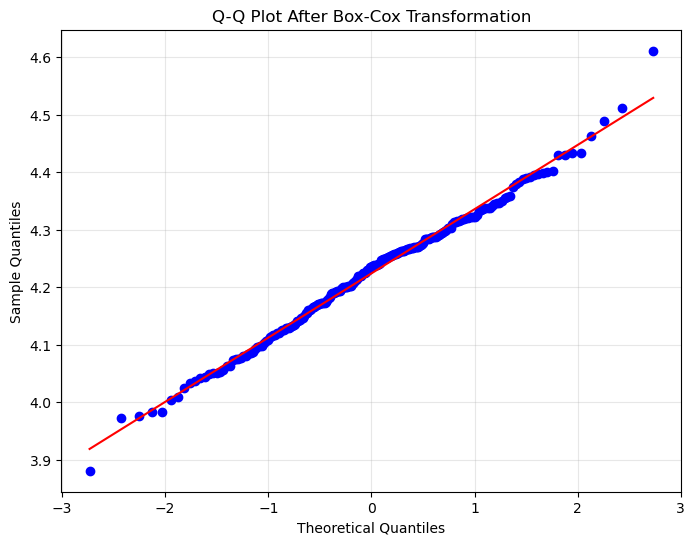

In [54]:
# Q-Q Plot After Box-Cox Transformation

plt.figure(figsize=(8, 6))

stats.probplot(
    boxcox_data,
    dist='norm',
    plot=plt
)

plt.title('Q-Q Plot After Box-Cox Transformation')
plt.xlabel('Theoretical Quantiles')
plt.ylabel('Sample Quantiles')

plt.grid(alpha=0.3)
plt.show()

### Box-Cox Transformation – Interpretation

Box-Cox Transformation was applied to
positive transaction amounts.

The optimal lambda parameter was estimated
automatically using the Box-Cox method.

Original and transformed distributions were
compared using histograms, skewness,
kurtosis and standard deviation.

The Shapiro-Wilk test and Q-Q Plot were also
used to examine normality after transformation.

The results help evaluate whether Box-Cox
Transformation improves the distribution
characteristics of transaction amounts.

##  Z-Score and Probability Analysis

### Objective

To calculate Z-scores for transaction amounts
and determine the probability of transactions
exceeding ₹5,000.

Theoretical and empirical probabilities
will be compared using statistical analysis.

In [55]:
# Z-Score Calculation

amounts = df['transaction_amount']

mean_amount = amounts.mean()
std_amount = amounts.std()

df['z_score'] = (
    (amounts - mean_amount) / std_amount
)

print("Mean Transaction Amount:", round(mean_amount, 2))
print("Standard Deviation:", round(std_amount, 2))

print("\nFirst 10 Z-Scores:")
display(df[['transaction_amount', 'z_score']].head(10))

Mean Transaction Amount: 3365.19
Standard Deviation: 1985.71

First 10 Z-Scores:


,transaction_amount,z_score
0,3821.34,0.229716
1,2781.84,-0.293776
2,4120.97,0.380609
3,6383.78,1.520159
4,2651.61,-0.359360
5,2651.63,-0.359350
6,6565.65,1.611748
7,4375.24,0.508659
8,2357.28,-0.507584
9,3909.95,0.274340


In [56]:
# Probability of Transactions Exceeding ₹5000

threshold = 5000

z_threshold = (
    (threshold - mean_amount) / std_amount
)

theoretical_probability = stats.norm.sf(z_threshold)

print("Threshold Amount: ₹", threshold)

print("Z-Score:", round(z_threshold, 4))

print(
    "Theoretical Probability:",
    round(theoretical_probability, 4)
)

print(
    "Theoretical Probability (%):",
    round(theoretical_probability * 100, 2), "%"
)

Threshold Amount: ₹ 5000
Z-Score: 0.8233
Theoretical Probability: 0.2052
Theoretical Probability (%): 20.52 %


In [57]:
# Empirical Probability

above_5000 = (amounts > threshold).sum()

total_transactions = len(amounts)

empirical_probability = (
    above_5000 / total_transactions
)

print("Total Transactions:", total_transactions)

print("Transactions Above ₹5000:", above_5000)

print(
    "Actual Probability (%):",
    round(empirical_probability * 100, 2), "%"
)

Total Transactions: 220
Transactions Above ₹5000: 25
Actual Probability (%): 11.36 %


In [58]:
# Theoretical vs Empirical Probability

probability_comparison = pd.DataFrame({
    'Method': [
        'Theoretical Normal Probability',
        'Actual Dataset Probability'
    ],
    'Probability': [
        theoretical_probability,
        empirical_probability
    ]
})

probability_comparison['Percentage'] = (
    probability_comparison['Probability'] * 100
)

display(probability_comparison.round(4))

,Method,Probability,Percentage
0,Theoretical Normal Probability,0.2052,20.5172
1,Actual Dataset Probability,0.1136,11.3636


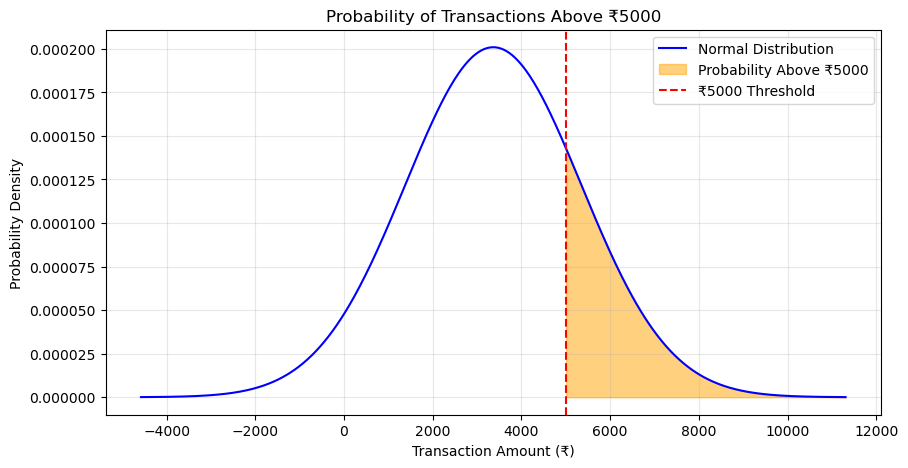

In [59]:
# Normal Distribution with ₹5000 Threshold

x_values = np.linspace(
    mean_amount - 4 * std_amount,
    mean_amount + 4 * std_amount,
    500
)

y_values = stats.norm.pdf(
    x_values,
    mean_amount,
    std_amount
)

plt.figure(figsize=(10, 5))

plt.plot(
    x_values,
    y_values,
    color='blue',
    label='Normal Distribution'
)

plt.fill_between(
    x_values,
    y_values,
    where=(x_values >= threshold),
    color='orange',
    alpha=0.5,
    label='Probability Above ₹5000'
)

plt.axvline(
    threshold,
    color='red',
    linestyle='--',
    label='₹5000 Threshold'
)

plt.title('Probability of Transactions Above ₹5000')
plt.xlabel('Transaction Amount (₹)')
plt.ylabel('Probability Density')

plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Z-Score and Probability – Interpretation

Z-scores were calculated for all transaction amounts
using the dataset mean and standard deviation.

The theoretical probability of transactions
exceeding ₹5,000 was estimated using
a fitted normal distribution.

The empirical probability was calculated
directly from the observed transaction data.

Both probabilities were compared to understand
the difference between the normal model
and actual customer transaction behavior.

The normal probability is an approximation
and depends on the normality assumption.

##  Probability Density Function (PDF)
## and Cumulative Distribution Function (CDF)

### Objective

To calculate and visualize PDF and CDF
for customer transaction amounts.

The analysis helps understand probability density
and cumulative transaction probabilities.

In [61]:
# Prepare Transaction Amounts

amounts = df['transaction_amount'].dropna()

amounts_sorted = np.sort(amounts)

print("Total Transactions:", len(amounts_sorted))
print("Minimum Amount:", amounts_sorted.min())
print("Maximum Amount:", amounts_sorted.max())

Total Transactions: 220
Minimum Amount: 804.42
Maximum Amount: 20462.84


In [62]:
# Probability Density Function (PDF)

from scipy.stats import gaussian_kde

kde = gaussian_kde(amounts_sorted)

x_pdf = np.linspace(
    amounts_sorted.min(),
    amounts_sorted.max(),
    500
)

pdf_values = kde(x_pdf)

print("PDF Calculation Completed!")
print("Number of PDF Points:", len(pdf_values))

PDF Calculation Completed!
Number of PDF Points: 500


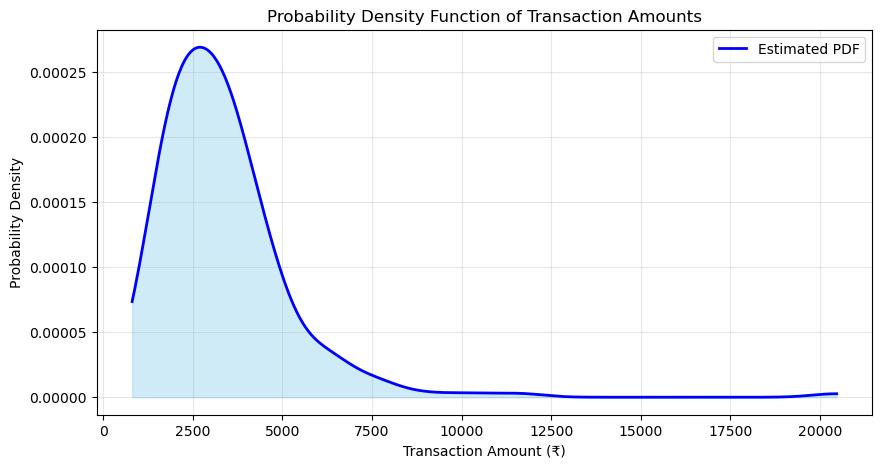

In [63]:
# PDF Graph

plt.figure(figsize=(10, 5))

plt.plot(
    x_pdf,
    pdf_values,
    color='blue',
    linewidth=2,
    label='Estimated PDF'
)

plt.fill_between(
    x_pdf,
    pdf_values,
    color='skyblue',
    alpha=0.4
)

plt.title('Probability Density Function of Transaction Amounts')
plt.xlabel('Transaction Amount (₹)')
plt.ylabel('Probability Density')

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [64]:
# Empirical Cumulative Distribution Function (CDF)

cdf_values = (
    np.arange(1, len(amounts_sorted) + 1)
    / len(amounts_sorted)
)

print("CDF Calculation Completed!")

print("First 10 CDF Values:")
print(cdf_values[:10])

CDF Calculation Completed!
First 10 CDF Values:
[0.00454545 0.00909091 0.01363636 0.01818182 0.02272727 0.02727273
 0.03181818 0.03636364 0.04090909 0.04545455]


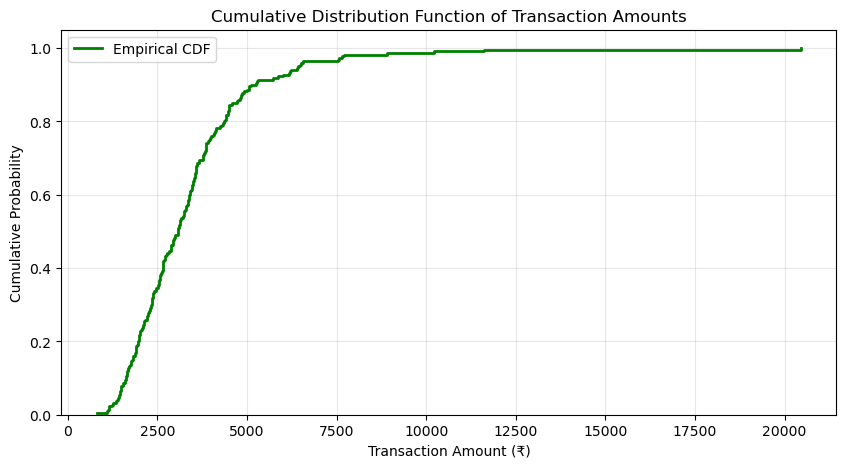

In [65]:
# CDF Graph

plt.figure(figsize=(10, 5))

plt.step(
    amounts_sorted,
    cdf_values,
    where='post',
    color='green',
    linewidth=2,
    label='Empirical CDF'
)

plt.title('Cumulative Distribution Function of Transaction Amounts')
plt.xlabel('Transaction Amount (₹)')
plt.ylabel('Cumulative Probability')

plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [66]:
# Cumulative Probability at ₹5000

threshold = 5000

below_threshold = (amounts <= threshold).sum()

total = len(amounts)

cdf_probability = below_threshold / total

above_threshold_probability = 1 - cdf_probability

print("Threshold: ₹", threshold)

print("Transactions <= ₹5000:", below_threshold)

print("Total Transactions:", total)

print(
    "CDF P(X <= 5000):",
    round(cdf_probability, 4)
)

print(
    "P(X > 5000):",
    round(above_threshold_probability, 4)
)

print(
    "Percentage <= ₹5000:",
    round(cdf_probability * 100, 2), "%"
)

Threshold: ₹ 5000
Transactions <= ₹5000: 195
Total Transactions: 220
CDF P(X <= 5000): 0.8864
P(X > 5000): 0.1136
Percentage <= ₹5000: 88.64 %


### PDF and CDF – Interpretation

The Probability Density Function was estimated
using Kernel Density Estimation (KDE).

The Cumulative Distribution Function was calculated
using the empirical transaction amounts.

The PDF graph shows the density pattern
of customer transaction amounts.

The CDF graph shows the cumulative proportion
of transactions up to different amount values.

The cumulative probability at ₹5,000 was also
calculated to understand the proportion of
transactions not exceeding this amount.

##  Best-Fit Distribution and Final Conclusion

### Objective

To compare Normal, Log-Normal and Power Law
distributions and identify the relatively
best-fitting statistical model for transaction amounts.

The comparison will use:
- Probability Density Functions
- Log-Likelihood
- Akaike Information Criterion (AIC)
- Kolmogorov-Smirnov (KS) Statistic

In [68]:
# Best-Fit Distribution Analysis

amounts = df['transaction_amount'].dropna()
amounts = amounts[amounts > 0]

# 1. Normal Distribution
normal_params = stats.norm.fit(amounts)

# 2. Log-Normal Distribution
lognorm_params_final = stats.lognorm.fit(
    amounts,
    floc=0
)

# 3. Power Law (Pareto) Distribution
pareto_params_final = stats.pareto.fit(
    amounts,
    floc=0
)

print("NORMAL PARAMETERS:")
print(normal_params)

print("\nLOG-NORMAL PARAMETERS:")
print(lognorm_params_final)

print("\nPOWER LAW (PARETO) PARAMETERS:")
print(pareto_params_final)

NORMAL PARAMETERS:
(np.float64(3365.1924090909088), np.float64(1981.1873022625773))

LOG-NORMAL PARAMETERS:
(np.float64(0.4749178350151927), 0, np.float64(2983.1591334067753))

POWER LAW (PARETO) PARAMETERS:
(np.float64(0.7629996393449987), 0, np.float64(804.42))


In [69]:
# Log-Likelihood Calculation

normal_ll = np.sum(
    stats.norm.logpdf(amounts, *normal_params)
)

lognorm_ll = np.sum(
    stats.lognorm.logpdf(
        amounts, *lognorm_params_final
    )
)

pareto_ll = np.sum(
    stats.pareto.logpdf(
        amounts, *pareto_params_final
    )
)

# AIC Calculation

normal_aic = 2 * 2 - 2 * normal_ll
lognorm_aic = 2 * 2 - 2 * lognorm_ll
pareto_aic = 2 * 2 - 2 * pareto_ll

# Comparison Table

model_comparison = pd.DataFrame({
    'Distribution': [
        'Normal',
        'Log-Normal',
        'Power Law (Pareto)'
    ],

    'Log_Likelihood': [
        normal_ll,
        lognorm_ll,
        pareto_ll
    ],

    'AIC': [
        normal_aic,
        lognorm_aic,
        pareto_aic
    ]
})

model_comparison = model_comparison.sort_values('AIC')

display(model_comparison.round(4))

,Distribution,Log_Likelihood,AIC
1,Log-Normal,-1908.5139,3821.0278
0,Normal,-1982.2858,3968.5717
2,Power Law (Pareto),-2039.6719,4083.3438


In [70]:
# Kolmogorov-Smirnov Test

ks_normal = stats.kstest(
    amounts,
    'norm',
    args=normal_params
)

ks_lognormal = stats.kstest(
    amounts,
    'lognorm',
    args=lognorm_params_final
)

ks_pareto = stats.kstest(
    amounts,
    'pareto',
    args=pareto_params_final
)

ks_comparison = pd.DataFrame({
    'Distribution': [
        'Normal',
        'Log-Normal',
        'Power Law (Pareto)'
    ],

    'KS_Statistic': [
        ks_normal.statistic,
        ks_lognormal.statistic,
        ks_pareto.statistic
    ],

    'KS_P_Value': [
        ks_normal.pvalue,
        ks_lognormal.pvalue,
        ks_pareto.pvalue
    ]
})

display(ks_comparison.round(5))

,Distribution,KS_Statistic,KS_P_Value
0,Normal,0.14038,0.00030
1,Log-Normal,0.03779,0.89988
2,Power Law (Pareto),0.32160,0.00000


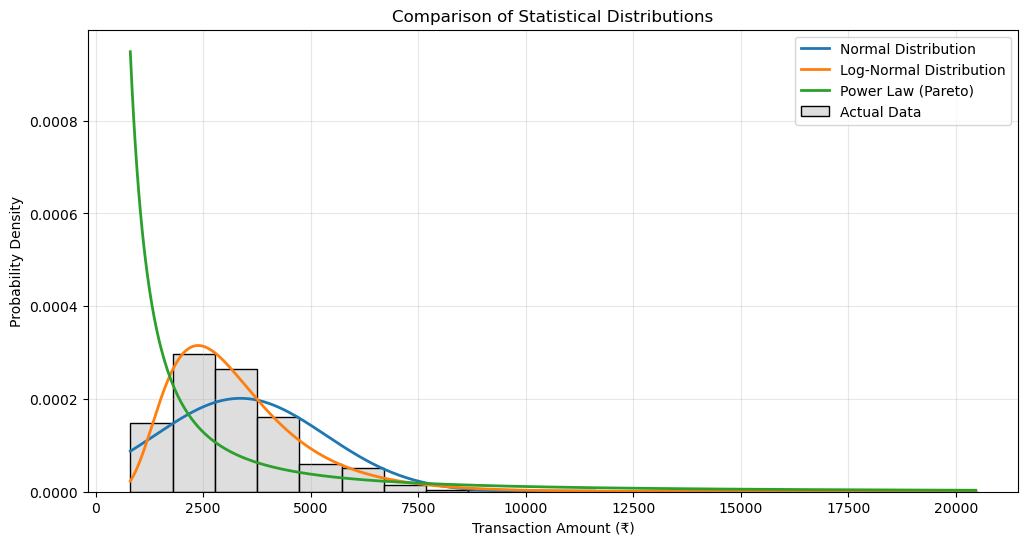

In [71]:
# Distribution Comparison Graph

x_fit = np.linspace(
    amounts.min(),
    amounts.max(),
    500
)

normal_pdf = stats.norm.pdf(
    x_fit, *normal_params
)

lognormal_pdf = stats.lognorm.pdf(
    x_fit, *lognorm_params_final
)

pareto_pdf = stats.pareto.pdf(
    x_fit, *pareto_params_final
)

plt.figure(figsize=(12, 6))

sns.histplot(
    amounts,
    bins=20,
    stat='density',
    color='lightgray',
    label='Actual Data'
)

plt.plot(
    x_fit,
    normal_pdf,
    label='Normal Distribution',
    linewidth=2
)

plt.plot(
    x_fit,
    lognormal_pdf,
    label='Log-Normal Distribution',
    linewidth=2
)

plt.plot(
    x_fit,
    pareto_pdf,
    label='Power Law (Pareto)',
    linewidth=2
)

plt.title('Comparison of Statistical Distributions')
plt.xlabel('Transaction Amount (₹)')
plt.ylabel('Probability Density')

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [72]:
# Best Model Based on AIC

best_model = model_comparison.iloc[0]['Distribution']

print("BEST MODEL BASED ON AIC:")
print(best_model)

print("\nAIC Comparison:")
display(model_comparison[['Distribution', 'AIC']])

BEST MODEL BASED ON AIC:
Log-Normal

AIC Comparison:


,Distribution,AIC
1,Log-Normal,3821.027805
0,Normal,3968.571655
2,Power Law (Pareto),4083.343774


# FINAL PROJECT CONCLUSION

The Spread Locator project analyzed customer
transaction behavior using statistical distributions
and probability analysis.

The project covered Bernoulli, Binomial, Poisson,
Normal, Log-Normal and Power Law distributions.

Q-Q plots and normality tests were used to examine
the distribution of transaction amounts.

Box-Cox Transformation was applied to study
the effect of transformation on skewness
and distribution characteristics.

Z-scores were calculated and the probability
of transactions exceeding ₹5,000 was analyzed.

PDF and CDF were generated to understand
transaction density and cumulative probability.

Normal, Log-Normal and Power Law models
were compared using AIC, Log-Likelihood,
KS statistics and graphical analysis.

The final model selection was based on
the comparative statistical results.

This project demonstrates how statistical
distributions can help an e-commerce business
understand customer purchasing behavior
and make data-driven decisions.